# Session 3 — Interaction effects

Econometrics (PhD), CGDE / IWH Halle — Felix Noth

Companion to lecture AE1.1 (Regression Review II, applied part). With an
interaction term the effect of one variable depends on the level of another,
so there is no longer "the" coefficient to report. This notebook works
through, with simulated data and a known truth:

1. The model and what each coefficient means — including why a
   coefficient on $x_1$ is *not* "the effect of $x_1$".
2. Marginal effects as a function of the moderator, with standard errors from
   the variance-covariance matrix (delta method).
3. The Brambor, Clark and Golder (2006) checklist: always include the
   constitutive terms, and what happens when you do not.
4. Binary × binary (the diff-in-diff shape), centering, and the power problem.

Requirements: `numpy`, `pandas`, `statsmodels`, `matplotlib`.


In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(20261026)
pd.set_option("display.precision", 4)

BLUE, ORANGE, VERMILLION, GREEN, GREY = "#0072B2", "#E69F00", "#D55E00", "#009E73", "#999999"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
    "font.family": "sans-serif",
})

def ols(formula, data):
    return smf.ols(formula, data=data).fit(cov_type="HC1")

def coef_table(*fits, names=None):
    names = names or [f"({i+1})" for i in range(len(fits))]
    rows = {}
    for f, nm in zip(fits, names):
        for p in f.params.index:
            rows.setdefault(p, {})[nm] = f"{f.params[p]:.3f} ({f.bse[p]:.3f})"
    return pd.DataFrame(rows).T.fillna("")


## 1. The model

$$y = \alpha + \beta_1 x_1 + \beta_2 x_2 + \beta_3\, x_1 x_2 + \varepsilon .$$

Partial derivatives:

$$\frac{\partial y}{\partial x_1} = \beta_1 + \beta_3 x_2, \qquad
  \frac{\partial y}{\partial x_2} = \beta_2 + \beta_3 x_1 .$$

So $\beta_1$ is the effect of $x_1$ **when $x_2 = 0$** — not an average
effect, not "the main effect" — and $\beta_3$ is how much that effect changes
per unit of $x_2$. Whether "$x_2 = 0$" is a meaningful point depends entirely
on the scale of $x_2$.

Running example: $y$ = firm investment rate, $x_1$ = a policy-rate cut
(continuous, in percentage points), $x_2$ = the firm's leverage. The story:
rate cuts stimulate investment, more so for highly levered firms.


In [2]:
n = 3000
cut = rng.uniform(0, 2, n)                 # size of the rate cut, 0-2 pp
lev = rng.beta(2, 3, n) * 100              # leverage in %, mean 40
a, b1, b2, b3 = 5.0, 0.5, -0.05, 0.03      # truth: effect of a cut = 0.5 + 0.03 * leverage
inv = a + b1 * cut + b2 * lev + b3 * cut * lev + rng.normal(0, 3, n)
df = pd.DataFrame({"inv": inv, "cut": cut, "lev": lev})

fit = ols("inv ~ cut * lev", df)           # 'cut * lev' = cut + lev + cut:lev
coef_table(fit, names=["full interaction model"])


,full interaction model
Intercept,4.668 (0.231)
cut,0.554 (0.203)
lev,-0.039 (0.005)
cut:lev,0.027 (0.005)


Read the table against the truth $(0.5, -0.05, 0.03)$: the coefficient on
`cut` (≈ 0.5) is the effect of a one-point cut for a firm with **zero
leverage**. For a firm with leverage 40 the effect is
$0.5 + 0.03 \times 40 = 1.7$ — more than three times larger. Reporting
"the coefficient on `cut`" would be wrong by that factor.


## 2. Marginal effects and their standard errors

The marginal effect of $x_1$ at a given $x_2$ is a linear combination of two
estimated coefficients,

$$\widehat{ME}(x_2) = \hat\beta_1 + \hat\beta_3\, x_2 = c'\hat\beta, \quad c = (0, 1, 0, x_2)',$$

so its variance follows from the variance-covariance matrix
$\hat V = \widehat{\mathrm{Var}}(\hat\beta)$ (Session 1):

$$\mathrm{Var}\big(\widehat{ME}(x_2)\big) = c'\hat V c
  = \mathrm{Var}(\hat\beta_1) + x_2^2\,\mathrm{Var}(\hat\beta_3) + 2 x_2\,\mathrm{Cov}(\hat\beta_1, \hat\beta_3).$$

This is the delta method for a linear function — the covariance term is
where the off-diagonal of $\hat V$ earns its keep. We compute it by hand and
plot the effect over the range of the moderator.


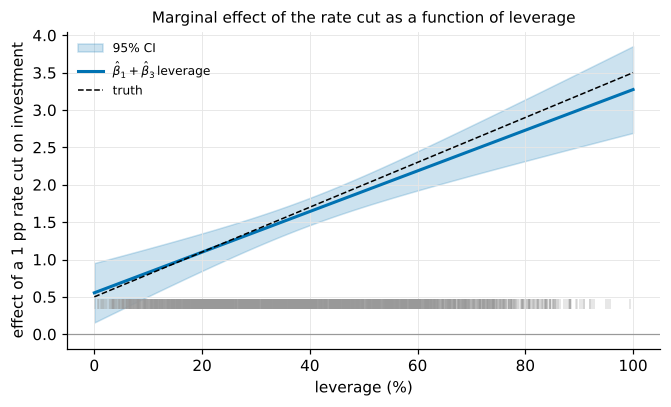

leverage   0: effect = 0.554  (se 0.203)   truth 0.500
leverage  20: effect = 1.098  (se 0.128)   truth 1.100
leverage  40: effect = 1.642  (se 0.093)   truth 1.700
leverage  60: effect = 2.186  (se 0.134)   truth 2.300
leverage  80: effect = 2.730  (se 0.211)   truth 2.900


In [3]:
V = fit.cov_params()
names = list(fit.params.index)                   # ['Intercept', 'cut', 'lev', 'cut:lev']

def marginal_effect(x2):
    c = np.zeros(len(names)); c[names.index("cut")] = 1; c[names.index("cut:lev")] = x2
    me = c @ fit.params.values
    se = np.sqrt(c @ V.values @ c)
    return me, se

grid = np.linspace(0, 100, 101)
me, se = np.array([marginal_effect(g) for g in grid]).T
z = stats.norm.ppf(0.975)

fig, ax = plt.subplots(figsize=(6.2, 3.8))
ax.fill_between(grid, me - z * se, me + z * se, color=BLUE, alpha=0.2, label="95% CI")
ax.plot(grid, me, color=BLUE, lw=2, label=r"$\hat\beta_1 + \hat\beta_3\,$leverage")
ax.plot(grid, b1 + b3 * grid, color="black", lw=1, ls="--", label="truth")
ax.axhline(0, color=GREY, lw=0.8)
# rug: where the data actually are
ax.plot(df.lev, np.full(n, me.min() - 0.15), "|", color=GREY, alpha=0.3, ms=6)
ax.set_xlabel("leverage (%)"); ax.set_ylabel("effect of a 1 pp rate cut on investment")
ax.set_title("Marginal effect of the rate cut as a function of leverage", fontsize=10)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

for g in [0, 20, 40, 60, 80]:
    m, s = marginal_effect(g)
    print(f"leverage {g:>3}: effect = {m:.3f}  (se {s:.3f})   truth {b1 + b3*g:.3f}")


Three things to take from the figure:

- The confidence band is narrowest where the data are dense (around the mean
  of the moderator) and fans out towards the edges — the covariance term at
  work.
- A test of "$\beta_3 = 0$" asks whether the *line is flat*. A test of
  "$\beta_1 = 0$" asks whether the effect is zero *at $x_2 = 0$*, which may be
  a leverage level no firm has. Neither is "is there an effect of rate cuts?"
- The rug marks remind you to interpret the effect only over the observed
  support of the moderator.

`statsmodels` does the same arithmetic for any linear combination via
`t_test`; the numbers match our hand computation.


In [4]:
for g in [0, 40, 80]:
    res = fit.t_test(f"cut + {g} * cut:lev = 0")
    print(f"leverage {g:>2}: {res.effect[0]:.3f} (se {res.sd[0][0]:.3f}), t = {res.tvalue[0][0]:.2f}")


leverage  0: 0.554 (se 0.203), t = 2.73
leverage 40: 1.642 (se 0.093), t = 17.65
leverage 80: 2.730 (se 0.211), t = 12.97


## 3. The checklist (Brambor, Clark and Golder 2006)

1. **Include all constitutive terms.** If $x_1 x_2$ is in the model, so must
   be $x_1$ and $x_2$ — even if they are "insignificant", even if theory says
   one of them has no direct effect.
2. **Do not interpret constitutive terms as unconditional effects.** $\beta_1$
   is the effect at $x_2 = 0$ (Part 1).
3. **Compute marginal effects and standard errors over the range of the
   moderator** (Part 2), not just the sign and significance of $\beta_3$.

Why rule 1 matters: omitting $x_2$ forces the interaction term to pick up
$x_2$'s own effect. With our DGP, where leverage has a *negative* direct
effect on investment, this flips the story.


In [5]:
fit_full  = ols("inv ~ cut + lev + cut:lev", df)
fit_no_x2 = ols("inv ~ cut + cut:lev", df)          # drops leverage's main effect
fit_no_x1 = ols("inv ~ lev + cut:lev", df)          # drops the rate cut's main effect
fit_none  = ols("inv ~ cut:lev", df)                # interaction only
coef_table(fit_full, fit_no_x2, fit_no_x1, fit_none,
           names=["full", "drop lev", "drop cut", "interaction only"])


,full,drop lev,drop cut,interaction only
Intercept,4.668 (0.231),3.111 (0.108),5.210 (0.118),3.964 (0.087)
cut,0.554 (0.203),1.734 (0.133),,
lev,-0.039 (0.005),,-0.050 (0.003),
cut:lev,0.027 (0.005),-0.002 (0.002),0.038 (0.002),0.019 (0.002)


Truth: $\beta_1 = 0.5,\ \beta_2 = -0.05,\ \beta_3 = 0.03$. Dropping the
leverage main effect makes the interaction *disappear* — the coefficient
collapses to zero and the model reports that rate cuts work the same for every
firm — because `cut:lev` is now the only term that moves with leverage and has
to absorb leverage's negative direct effect. Dropping `cut` biases $\beta_3$
upward instead, and the interaction-only model is wrong on everything. A theory that "leverage has no
direct effect" is not a license to drop the term: if it is true, its
coefficient will be near zero and nothing is lost; if it is false, everything
is.


## 4. Three practical cases

### 4.1 Binary × binary: the difference-in-differences shape

With two dummies, the interaction model is saturated — four cells, four
parameters — and every coefficient is a difference of cell means:

| | $x_2 = 0$ | $x_2 = 1$ |
|---|---|---|
| $x_1 = 0$ | $\alpha$ | $\alpha + \beta_2$ |
| $x_1 = 1$ | $\alpha + \beta_1$ | $\alpha + \beta_1 + \beta_2 + \beta_3$ |

$\beta_3$ is the difference in differences. This is the regression you will
run in the DiD sessions; today it is just an interaction.


In [6]:
n = 4000
treated = rng.binomial(1, 0.5, n)
post = rng.binomial(1, 0.5, n)
y = 10 + 2 * treated + 1 * post + 1.5 * treated * post + rng.normal(0, 2, n)
dd = pd.DataFrame({"y": y, "treated": treated, "post": post})

means = dd.groupby(["treated", "post"]).y.mean().unstack()
means.columns = ["post = 0", "post = 1"]; means.index = ["treated = 0", "treated = 1"]
print("cell means:\n", means.round(3), "\n")
did_by_hand = (means.iloc[1, 1] - means.iloc[1, 0]) - (means.iloc[0, 1] - means.iloc[0, 0])
fit_dd = ols("y ~ treated * post", dd)
print(f"DiD by hand: {did_by_hand:.4f}   regression coefficient on treated:post: {fit_dd.params['treated:post']:.4f}   (truth 1.5)")


cell means:
              post = 0  post = 1
treated = 0     9.956    11.045
treated = 1    12.045    14.479 

DiD by hand: 1.3448   regression coefficient on treated:post: 1.3448   (truth 1.5)


### 4.2 Centering the moderator

Nothing about the model changes if we replace $x_2$ by $x_2 - \bar x_2$; the
interaction coefficient and the fit are identical. What changes is the
*meaning* of $\beta_1$: it becomes the effect of $x_1$ at the **mean** of
$x_2$, which is usually the number people actually want when they say "the
effect of $x_1$". Centering is a presentation choice, not an estimation
choice.


In [7]:
df["lev_c"] = df.lev - df.lev.mean()
fit_c = ols("inv ~ cut * lev_c", df)
coef_table(fit, fit_c, names=["leverage raw", "leverage centered"])


,leverage raw,leverage centered
Intercept,4.668 (0.231),3.105 (0.106)
cut,0.554 (0.203),1.641 (0.093)
lev,-0.039 (0.005),
cut:lev,0.027 (0.005),
lev_c,,-0.039 (0.005)
cut:lev_c,,0.027 (0.005)


In [8]:
me_mean, se_mean = marginal_effect(df.lev.mean())
print(f"effect of a cut at mean leverage ({df.lev.mean():.1f} %) from the raw model:      {me_mean:.3f} (se {se_mean:.3f})")
print(f"coefficient on 'cut' in the centered model:                           {fit_c.params['cut']:.3f} (se {fit_c.bse['cut']:.3f})")
print(f"interaction coefficient, raw vs centered: {fit.params['cut:lev']:.4f} vs {fit_c.params['cut:lev_c']:.4f}")


effect of a cut at mean leverage (40.0 %) from the raw model:      1.641 (se 0.093)
coefficient on 'cut' in the centered model:                           1.641 (se 0.093)
interaction coefficient, raw vs centered: 0.0272 vs 0.0272


### 4.3 Interactions are noisy: the "16 times" rule

Gelman (2018): to detect an interaction of half the size of a main effect
with the same power, you need about **16 times** the sample size. The
interaction is estimated from the *difference* in slopes between groups, and
differences are always noisier than levels. A quick simulation: a binary
moderator, a main effect of 1 and an interaction of 0.5, same $n$ — compare
the standard errors.


In [9]:
def one_draw(n):
    x = rng.normal(0, 1, n); g = rng.binomial(1, 0.5, n)
    y = 1.0 * x + 0.5 * x * g + rng.normal(0, 1, n)
    d = pd.DataFrame({"y": y, "x": x, "g": g})
    f_main = smf.ols("y ~ x", data=d).fit()          # the main effect, pooled over both groups
    f_int  = smf.ols("y ~ x * g", data=d).fit()      # the interaction: difference in slopes
    return f_main.bse["x"], f_int.bse["x:g"], f_main.pvalues["x"] < 0.05, f_int.pvalues["x:g"] < 0.05

R = 500
out = np.array([one_draw(100) for _ in range(R)])
print(f"n = 100, {R} replications; main effect = 1, interaction = 0.5")
print(f"  se(main effect, pooled) ≈ {out[:,0].mean():.3f}    power: {out[:,2].mean():.2f}")
print(f"  se(interaction)         ≈ {out[:,1].mean():.3f}    power: {out[:,3].mean():.2f}")
ratio = (out[:,1].mean() / out[:,0].mean())**2
print(f"  variance ratio ≈ {ratio:.1f}; the interaction is also half the size -> noise-to-signal x {4*ratio:.0f}")


n = 100, 500 replications; main effect = 1, interaction = 0.5
  se(main effect, pooled) ≈ 0.104    power: 1.00
  se(interaction)         ≈ 0.207    power: 0.66
  variance ratio ≈ 3.9; the interaction is also half the size -> noise-to-signal x 16


The standard error of the interaction is about twice that of the pooled
main effect (it is a *difference* of two slopes, each estimated on half the
sample: variance $2 \times 2 = 4$ times larger), and the effect we are
looking for is half the size: four times the noise-to-signal ratio, sixteen
times the sample to compensate. Two consequences for practice:
decide on the interaction **before** looking at the data (otherwise you will
find one), and treat a "significant interaction" in a small sample with the
suspicion it deserves.


## 5. Exercises

1. **Where is the effect zero?** From the full model in Part 1, compute the
   leverage level at which the marginal effect of a rate cut crosses zero,
   with a confidence interval (hint: it is a ratio of coefficients — use the
   delta method or just invert the band in the plot). Is that level inside
   the support of the data?
2. **Nonlinearity or interaction?** Add `lev**2` to the DGP with a small
   coefficient and re-estimate the interaction model without the square.
   What happens to $\hat\beta_3$? (Interactions and omitted curvature are
   easily confused — Huntington-Klein, ch. 13.2.)
3. **Dummy × continuous.** Replace the continuous rate cut by a dummy
   (`cut > 1`) and re-run Parts 1–2. Write the two group-specific regression
   lines implied by the coefficients and plot them over the data.
4. **The 16-times rule.** Repeat the simulation of 4.3 for
   $n \in \{200, 800, 3200\}$ and plot power against $n$ for the main effect
   and the interaction. At which $n$ does the interaction reach the power the
   main effect had at $n = 200$?

## References

- Brambor, T., W. R. Clark and M. Golder (2006), "Understanding Interaction
  Models: Improving Empirical Analyses," *Political Analysis* 14(1), 63–82.
- Huntington-Klein (2025), *The Effect*, 2nd ed., ch. 13.2.4 (Interaction
  Terms) — [theeffectbook.net](https://theeffectbook.net/ch-StatisticalAdjustment.html).
- Gelman, A. (2018), "You need 16 times the sample size to estimate an
  interaction than to estimate a main effect," *Statistical Modeling, Causal
  Inference, and Social Science* (blog), March 15, 2018.
